# In this notebook we explore the respone terms of the single link

In [1]:
import h5py
import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("data/")
plt.rcParams['text.usetex'] = True

from lisaconstants import c
from lisaconstants.indexing import LINKS, SPACECRAFT
from pytdi.michelson import X2_ETA, Y2_ETA, Z2_ETA

from segwo.response import compute_strain2link
from segwo_utils import _link_response_boosted

from segwo_utils import InterpolatedOrbits, compute_covariance, compute_strain2x

import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')  # Suppress all warnings

/opt/miniconda3/envs/resp/lib/python3.12/site-packages/lisaconstants/compat/astropy.py:252: UserWarning: The following constants differ between lisaconstants and the version of astropy you have installed: VACUUM_PERMEABILITY. The recommended version of astropy is 7.2.0. Use a different one at your own risks. 
You may also open an issue at https://gitlab.esa.int/lisa-sgs/commons/lisa-constants to warn that lisaconstants is not compatible with astropy v8.0.2
  warnings.warn(


In [2]:
from cycler import cycler

COLORBLIND_PALETTE = [
    "#E69F00",  # orange
    "#56B4E9",  # sky blue
    "#009E73",  # bluish green
    "#F0E442",  # yellow
    "#0072B2",  # blue
    "#D55E00",  # vermillion
    "#CC79A7"   # reddish purple
]

plt.rcParams.update({
    'text.usetex':       True,        # set True if a LaTeX install is available
    'font.family':       'times',
    'font.size':         9,
    'axes.labelsize':    9,
    'axes.titlesize':    9,
    'xtick.labelsize':   8,
    'ytick.labelsize':   8,
    'legend.fontsize':   8,
    'legend.frameon':    True,
    'legend.framealpha': 0.8,
    'figure.dpi':        150,
    'savefig.dpi':       300,
    'savefig.bbox':      'tight',
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'grid.linestyle':    ':',
    'lines.linewidth':   1.5,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.prop_cycle':   cycler('color', COLORBLIND_PALETTE),
})

In [3]:
with h5py.File("data/processed_trajectories.h5", "r") as ds:
        t_orb_dataset   = ds["t_interp"][()]
        x_orb_dataset   = ds["spacecraft_positions"][()]
        v_orb_dataset   = ds["spacecraft_velocities"][()]
        ltts_dataset    = ds['owlt_12_23_31_13_32_21'][()]

t_orb        = t_orb_dataset
x_orb        = np.median(x_orb_dataset, axis=0)
v_orb        = np.median(v_orb_dataset, axis=0)
ltts_median  = np.median(ltts_dataset,  axis=0)

In [4]:
orbits = InterpolatedOrbits(t_orb, x_orb,
                                spacecraft_velocities=v_orb,
                                ltts=ltts_median,
                                interp_order=3)

In [5]:
array_ltts = np.arange(0,30,1) * 86400.0
print("Number of points in LISA", int(array_ltts[-1]*0.25))

Number of points in LISA 626400


# Inputs to Response

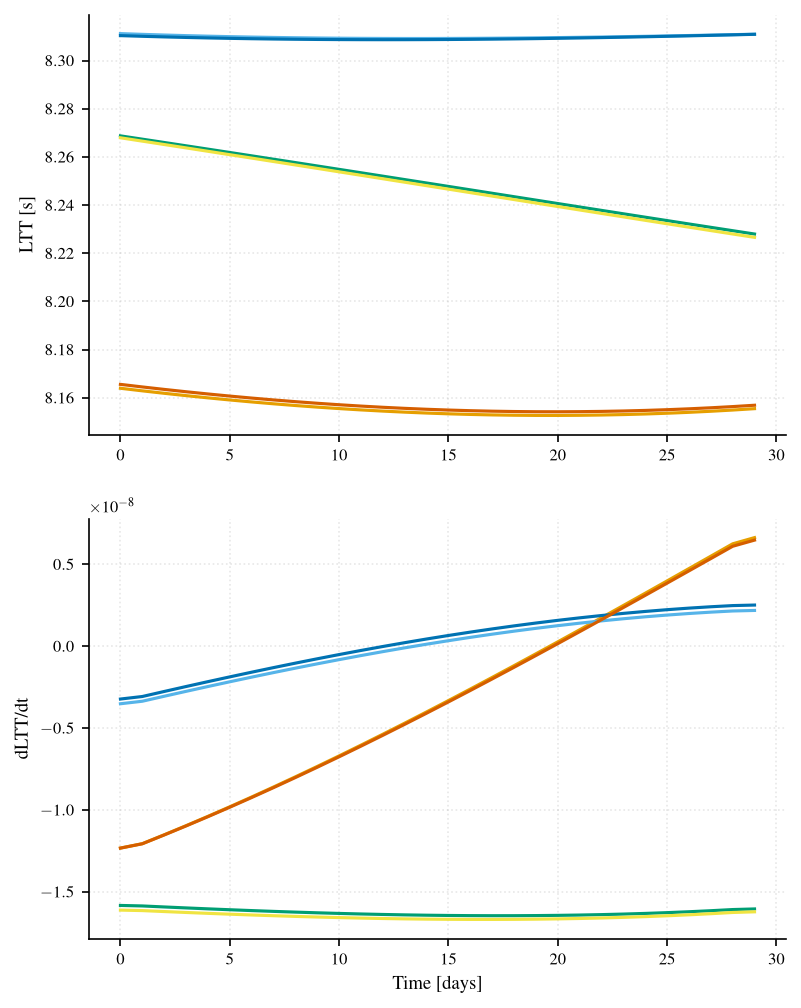

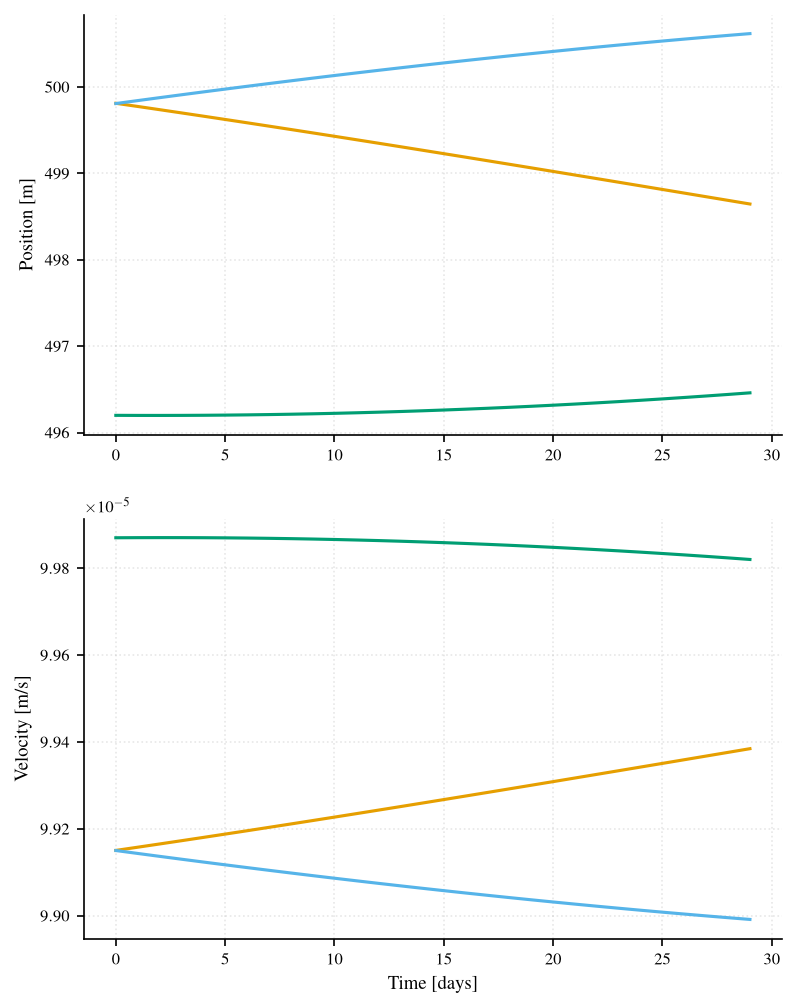

In [6]:
ltts      = orbits.compute_ltt(t=array_ltts)
positions = orbits.compute_position(t=array_ltts)
velocities = orbits.compute_velocity(t=array_ltts)

_, axes = plt.subplots(2, 1,figsize=(6,8))
for index, link in enumerate(LINKS):
    axes[0].plot(array_ltts/86400, ltts[:, index], label=link)
    axes[1].plot(array_ltts/86400, np.gradient(ltts[:, index], array_ltts), label=link)

plt.xlabel('Time [days]')
axes[0].set_ylabel('LTT [s]')
axes[1].set_ylabel(' dLTT/dt')
plt.show()

_, axes = plt.subplots(2, 1,figsize=(6,8))
for index, link in enumerate(SPACECRAFT):
    axes[0].plot(array_ltts/86400, np.linalg.norm(positions[:, index]/c, axis=1), label=link)
    axes[1].plot(array_ltts/86400, np.linalg.norm(velocities[:, index]/c, axis=1), label=link)

plt.xlabel('Time [days]')
axes[0].set_ylabel('Position [m]')
axes[1].set_ylabel('Velocity [m/s]')
plt.show()

# Response

In [7]:
nside = 2
npix  = hp.nside2npix(nside)
thetas, phis = hp.pix2ang(nside, np.arange(npix))
betas, lambs = np.pi / 2 - thetas, phis
f = np.logspace(-4, 0., 500)

strain2link = compute_strain2link(f, betas, lambs, ltts, positions, method="baghi+23")
test_zero_v_retTrue = _link_response_boosted(f, betas, lambs, ltts, positions, velocities=None, retarded=True, terms=("stat", "red", "pa1", "pa2", "defl", "sc"))
test_zero_v_retFalse = _link_response_boosted(f, betas, lambs, ltts, positions, velocities=None, retarded=False, terms=("stat", "red", "pa1", "pa2", "defl", "sc"))
strain2link_boosted = _link_response_boosted(f, betas, lambs, ltts, positions, velocities=velocities*1.0, terms=("stat", "red", "pa1", "pa2", "defl", "sc"))

print("Max relative difference between strain2link and test_zero_v_retFalse:", np.abs(1-strain2link / test_zero_v_retFalse).max())
print("Max relative difference between strain2link and test_zero_v_retTrue:", np.abs(1-strain2link / test_zero_v_retTrue).max())
print("Max relative difference between strain2link and strain2link_boosted:", np.abs(1-strain2link / strain2link_boosted).max())

Max relative difference between strain2link and test_zero_v_retFalse: 3.662625758733586e-13
Max relative difference between strain2link and test_zero_v_retTrue: 1.4134693420511911e-10
Max relative difference between strain2link and strain2link_boosted: 350.90805525212244


In [8]:
link_index = 0  # Choose A, E, or T
pol_index = 0  # Choose polarization
sky_index = 0  # Choose a specific sky location (pixel index)
time_index = 0  # Choose a specific time index

response = strain2link[:, :, sky_index, link_index, pol_index]
boosted_response = strain2link_boosted[:, :, sky_index, link_index, pol_index]

def get_time_freq_response(input_terms=("stat", "red", "pa1", "pa2", "defl", "sc")):
    return _link_response_boosted(f, betas, lambs, ltts, positions, velocities=velocities, terms=input_terms)

## Time evolution

In [9]:
(boosted_response == get_time_freq_response()[:, :, sky_index, link_index, pol_index]).all()

np.True_

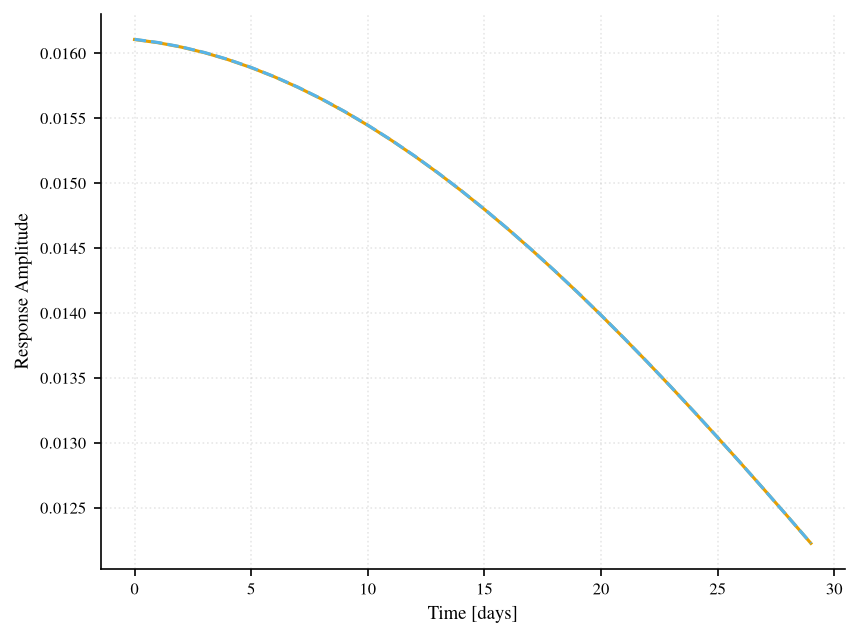

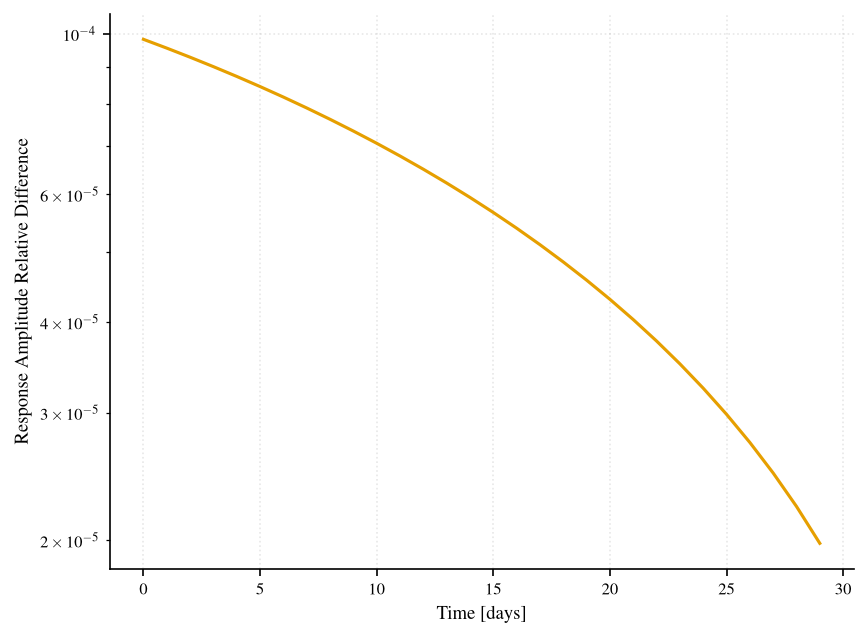

In [10]:
freq_ind = 100
plt.figure()
plt.plot(array_ltts/86400, np.abs(response[:,freq_ind]))
plt.plot(array_ltts/86400, np.abs(boosted_response[:,freq_ind]), ls='--', label='Boosted')
plt.xlabel('Time [days]')
plt.ylabel('Response Amplitude')
plt.show()

plt.figure()
plt.semilogy(array_ltts/86400, np.abs(1-np.abs(response[:,freq_ind])/np.abs(boosted_response[:,freq_ind])))
plt.xlabel('Time [days]')
plt.ylabel('Response Amplitude Relative Difference')
plt.show()

## Frequency evolution

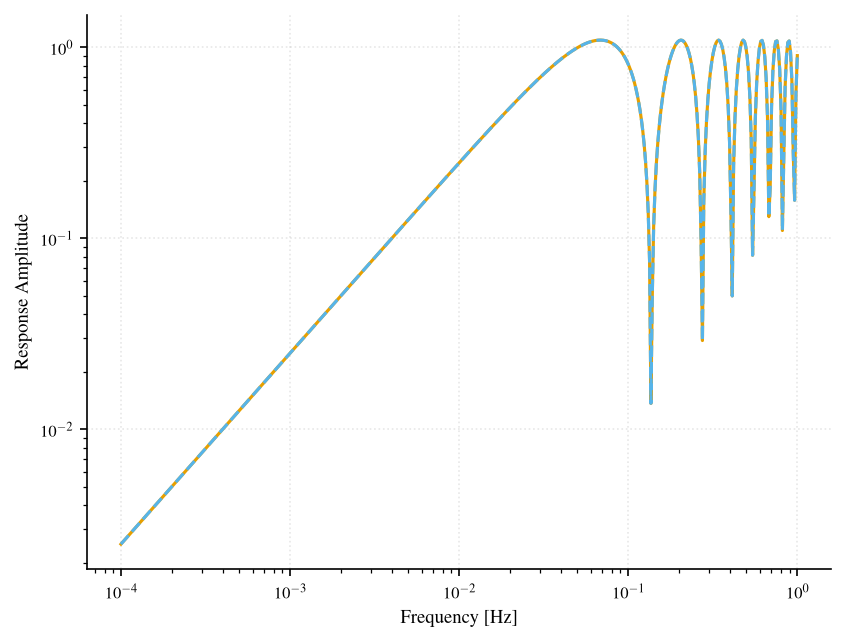

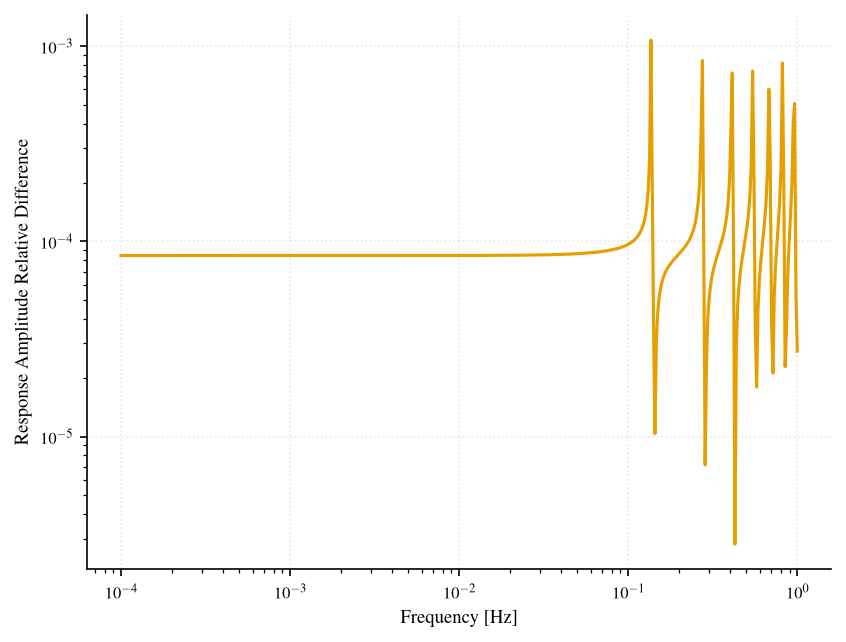

In [11]:
time_ind = 5
plt.figure()
plt.plot(f, np.abs(response[time_ind,:]))
plt.loglog(f, np.abs(boosted_response[time_ind,:]), ls='--', label='Boosted')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Response Amplitude')
plt.show()

# show relative difference between the two responses
plt.figure()
plt.loglog(f, np.abs(1-np.abs(response[time_ind,:])/np.abs(boosted_response[time_ind,:])))
plt.xlabel('Frequency [Hz]')
plt.ylabel('Response Amplitude Relative Difference')
plt.show()

## Term by term

stat (500, 48, 6, 2)
red (500, 48, 6, 2)
pa1 (500, 48, 6, 2)
pa2 (500, 48, 6, 2)
defl (500, 48, 6, 2)
sc (500, 48, 6, 2)


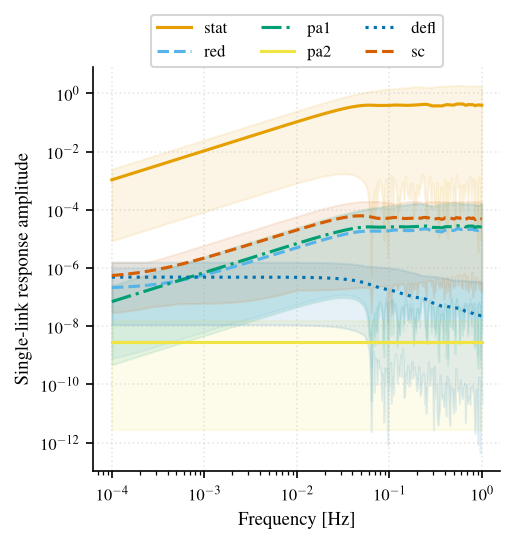

In [22]:
plt.figure(figsize=(3.5, 3.5))
line_styles = ['-', '--', '-.', '-', ':',  '--']
for el, color, ls in zip(["stat", "red", "pa1", "pa2", "defl", "sc"], COLORBLIND_PALETTE, line_styles):
    toplot = np.abs(get_time_freq_response(input_terms=(el,))[time_ind,:])
    print(el, toplot.shape)
    toplot_mean = np.mean(toplot[:, ], axis=(1,2,3))
    toplot_max = np.max(toplot, axis=(1,2,3))
    toplot_min = np.min(toplot, axis=(1,2,3))
    plt.loglog(f, toplot_mean, label=el, color=color, ls=ls)
    plt.fill_between(f, toplot_min, toplot_max, color=color, alpha=0.1)
    # print(el, toplot.max())
plt.xlabel('Frequency [Hz]')
plt.ylabel('Single-link response amplitude')
plt.legend(ncols=3, loc='upper center', bbox_to_anchor=(0.5, 1.15))
plt.show()